# 1. Setup

In [123]:
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import time

# 2. Carregando o Dataset e inspeções iniciais

In [124]:
# data = pd.read_csv('/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv')
data = pd.read_csv('../data.csv', index_col=0)

data = data.dropna(how='all',axis='columns')

data.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# 3. Preparando a estrutura dos dados

In [125]:
TARGET_COLUMN = "diagnosis"

x = data.drop(columns=[TARGET_COLUMN])
y = data[TARGET_COLUMN]

x.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
842302,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
842517,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
84300903,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
84348301,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
84358402,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# 4. Inspeções finais dos dados

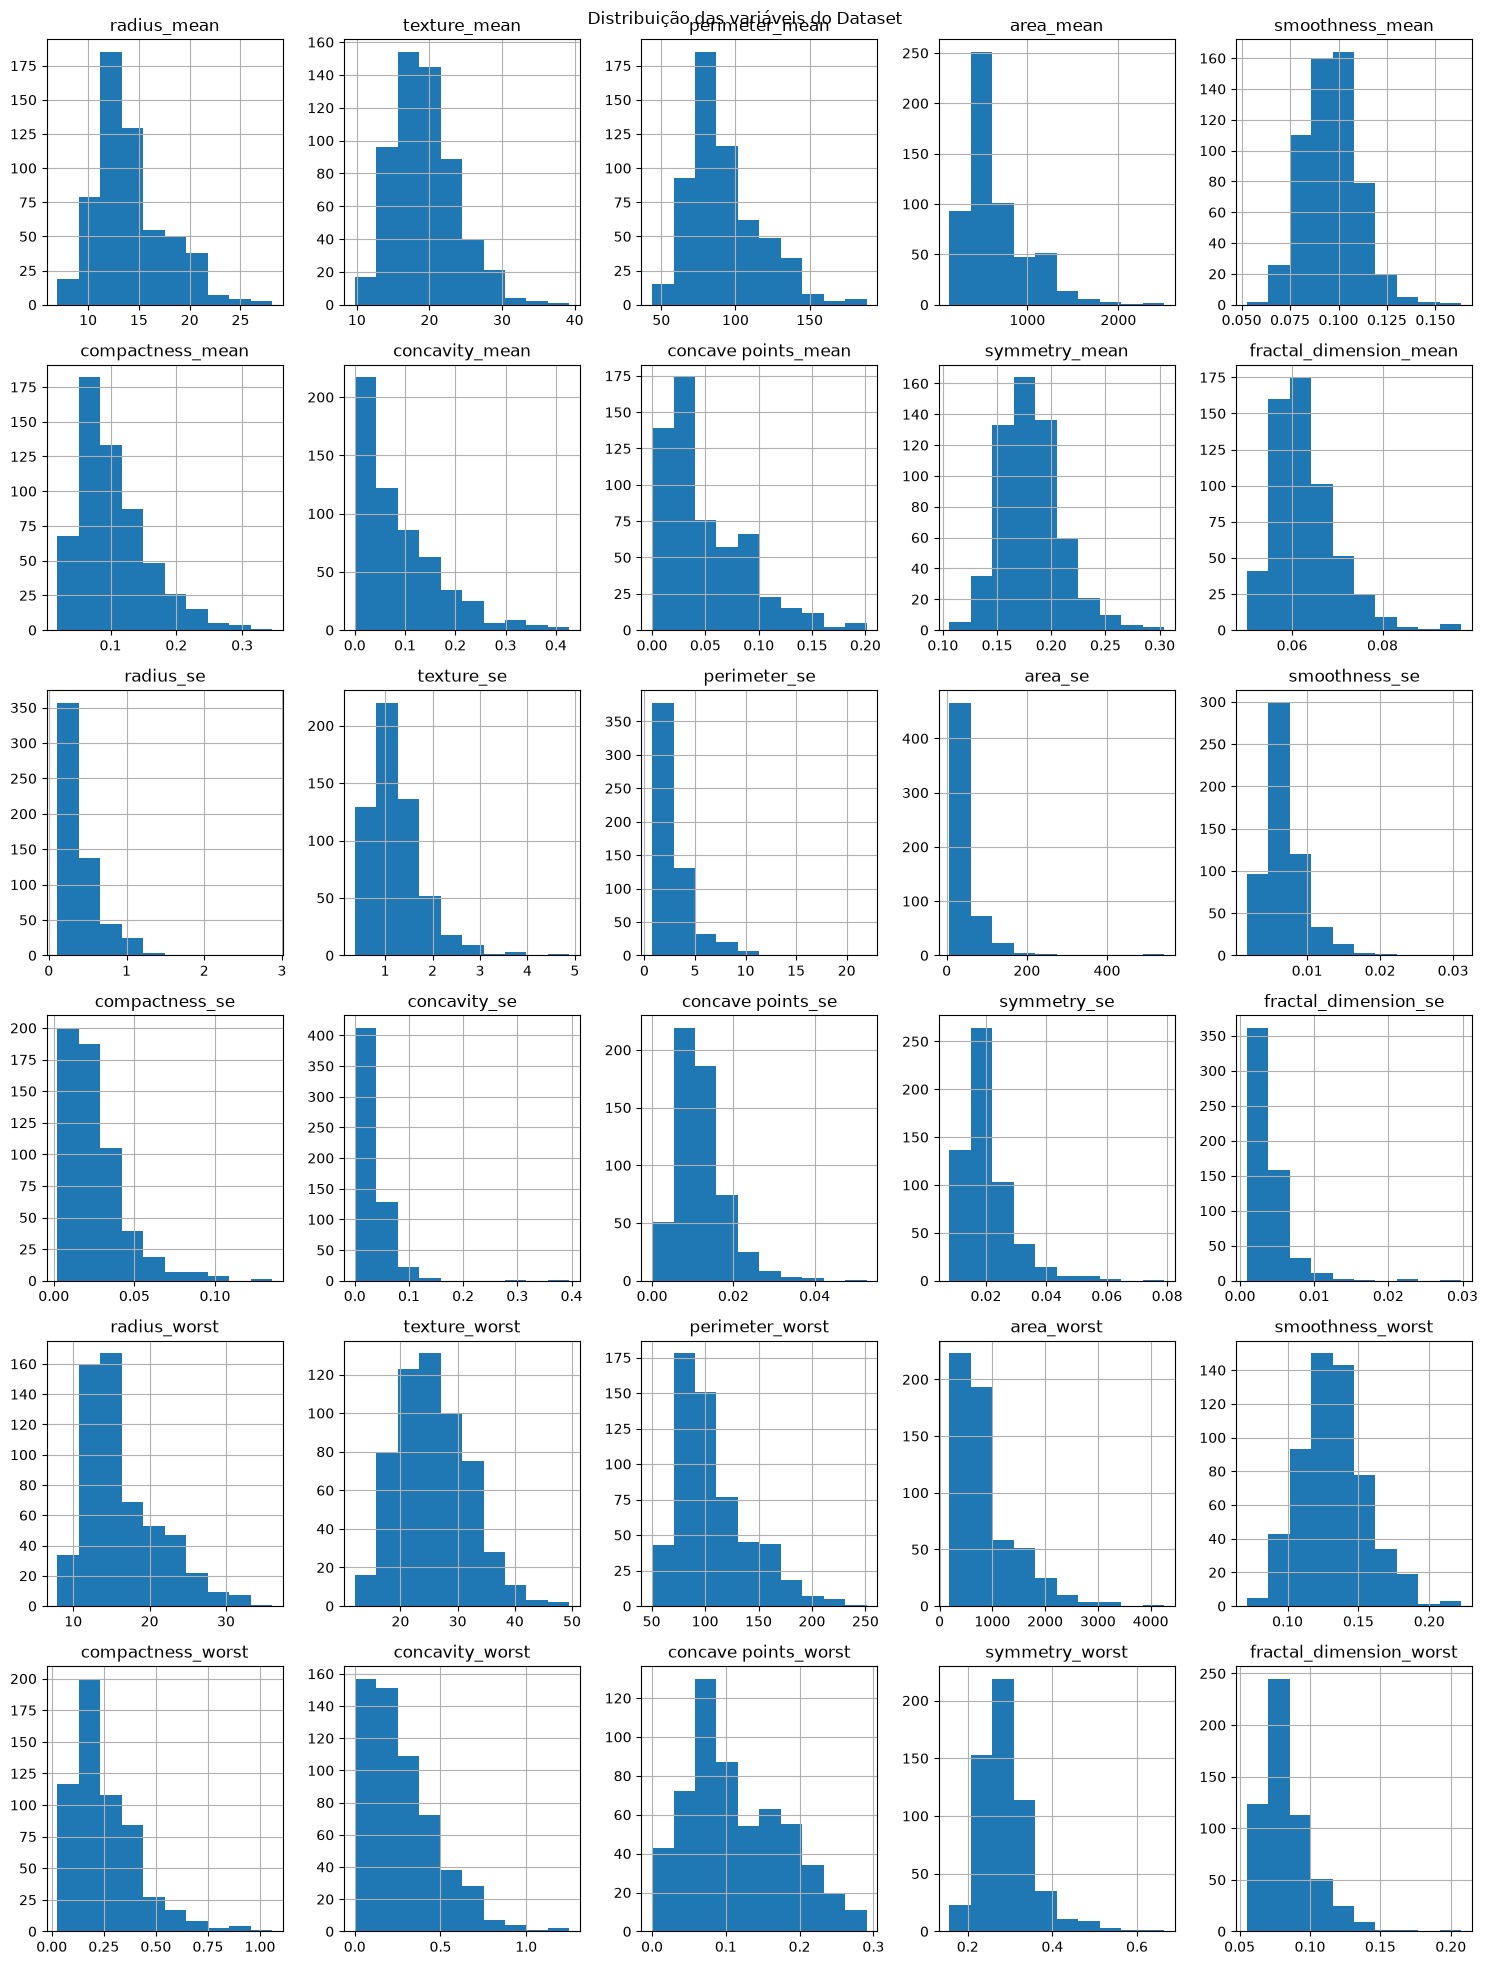

In [126]:
x[x.columns].hist(figsize=(15, 20))
plt.suptitle("Distribuição das variáveis do Dataset")
plt.tight_layout()
plt.show()

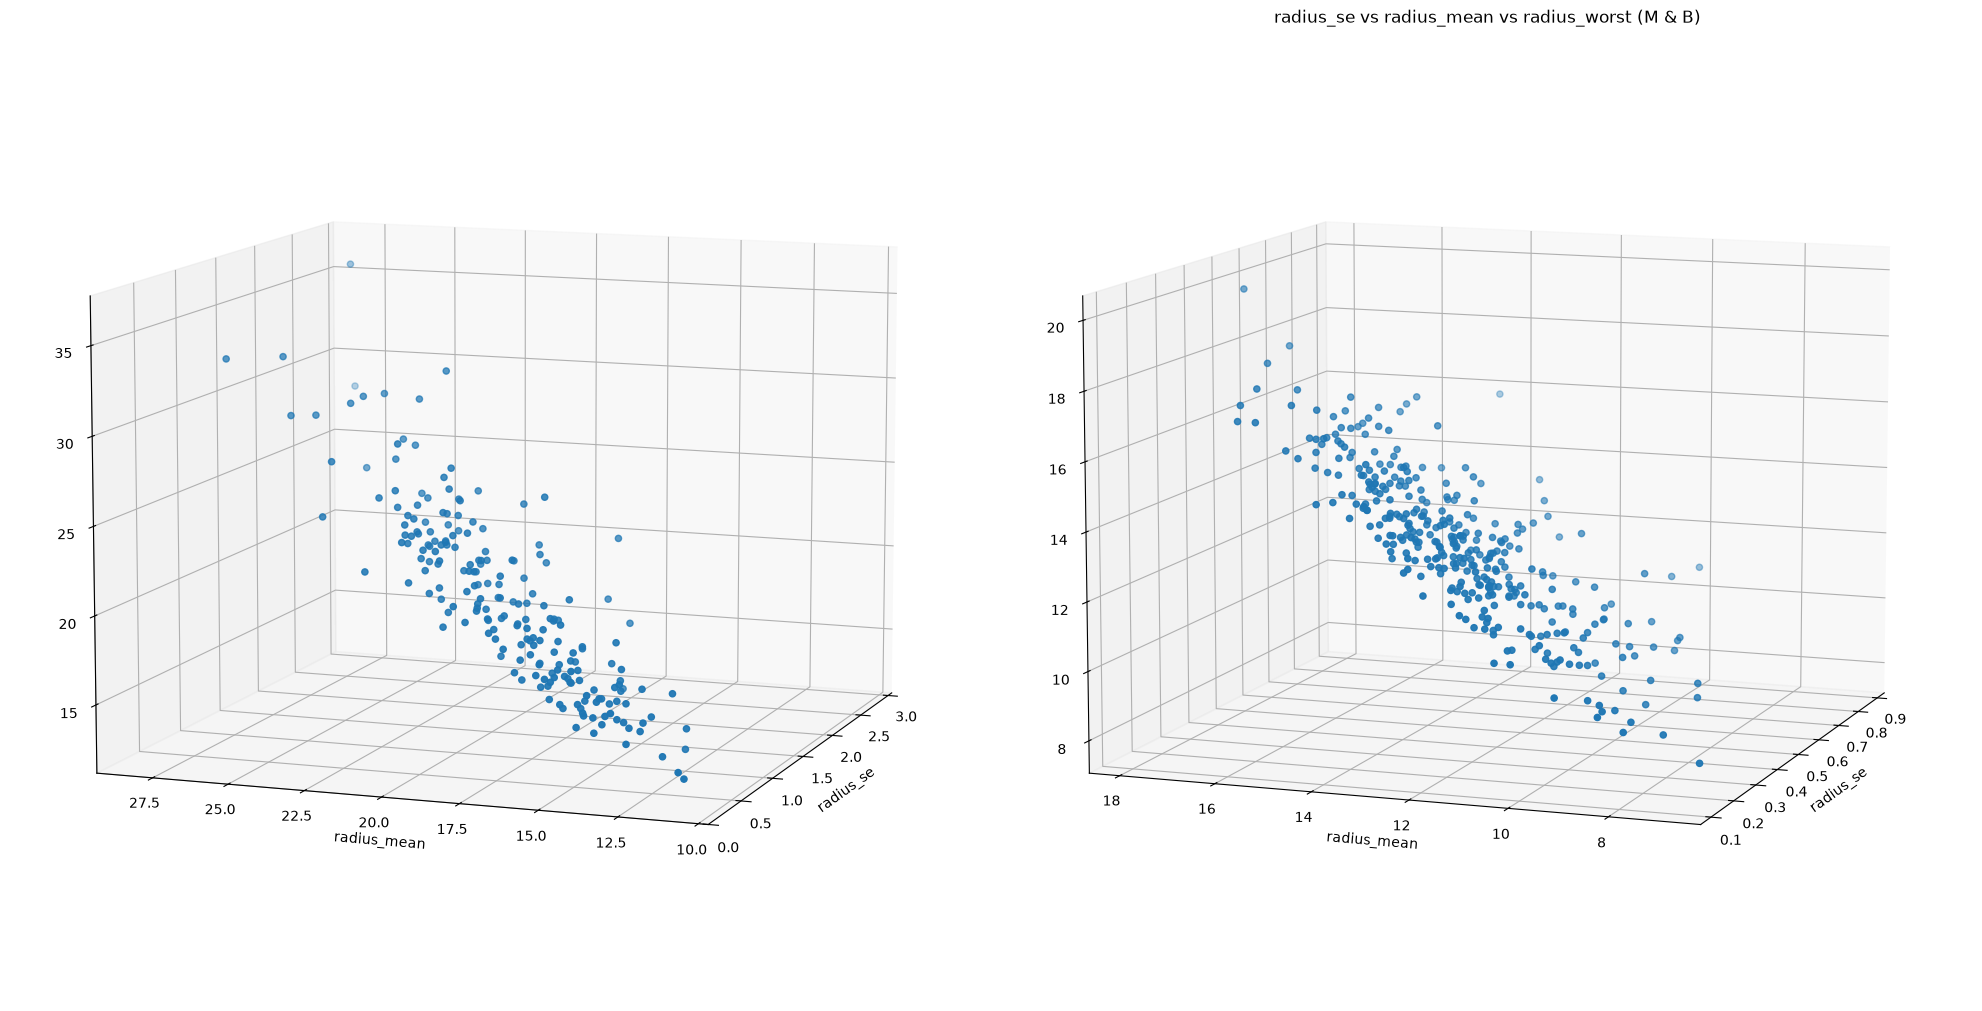

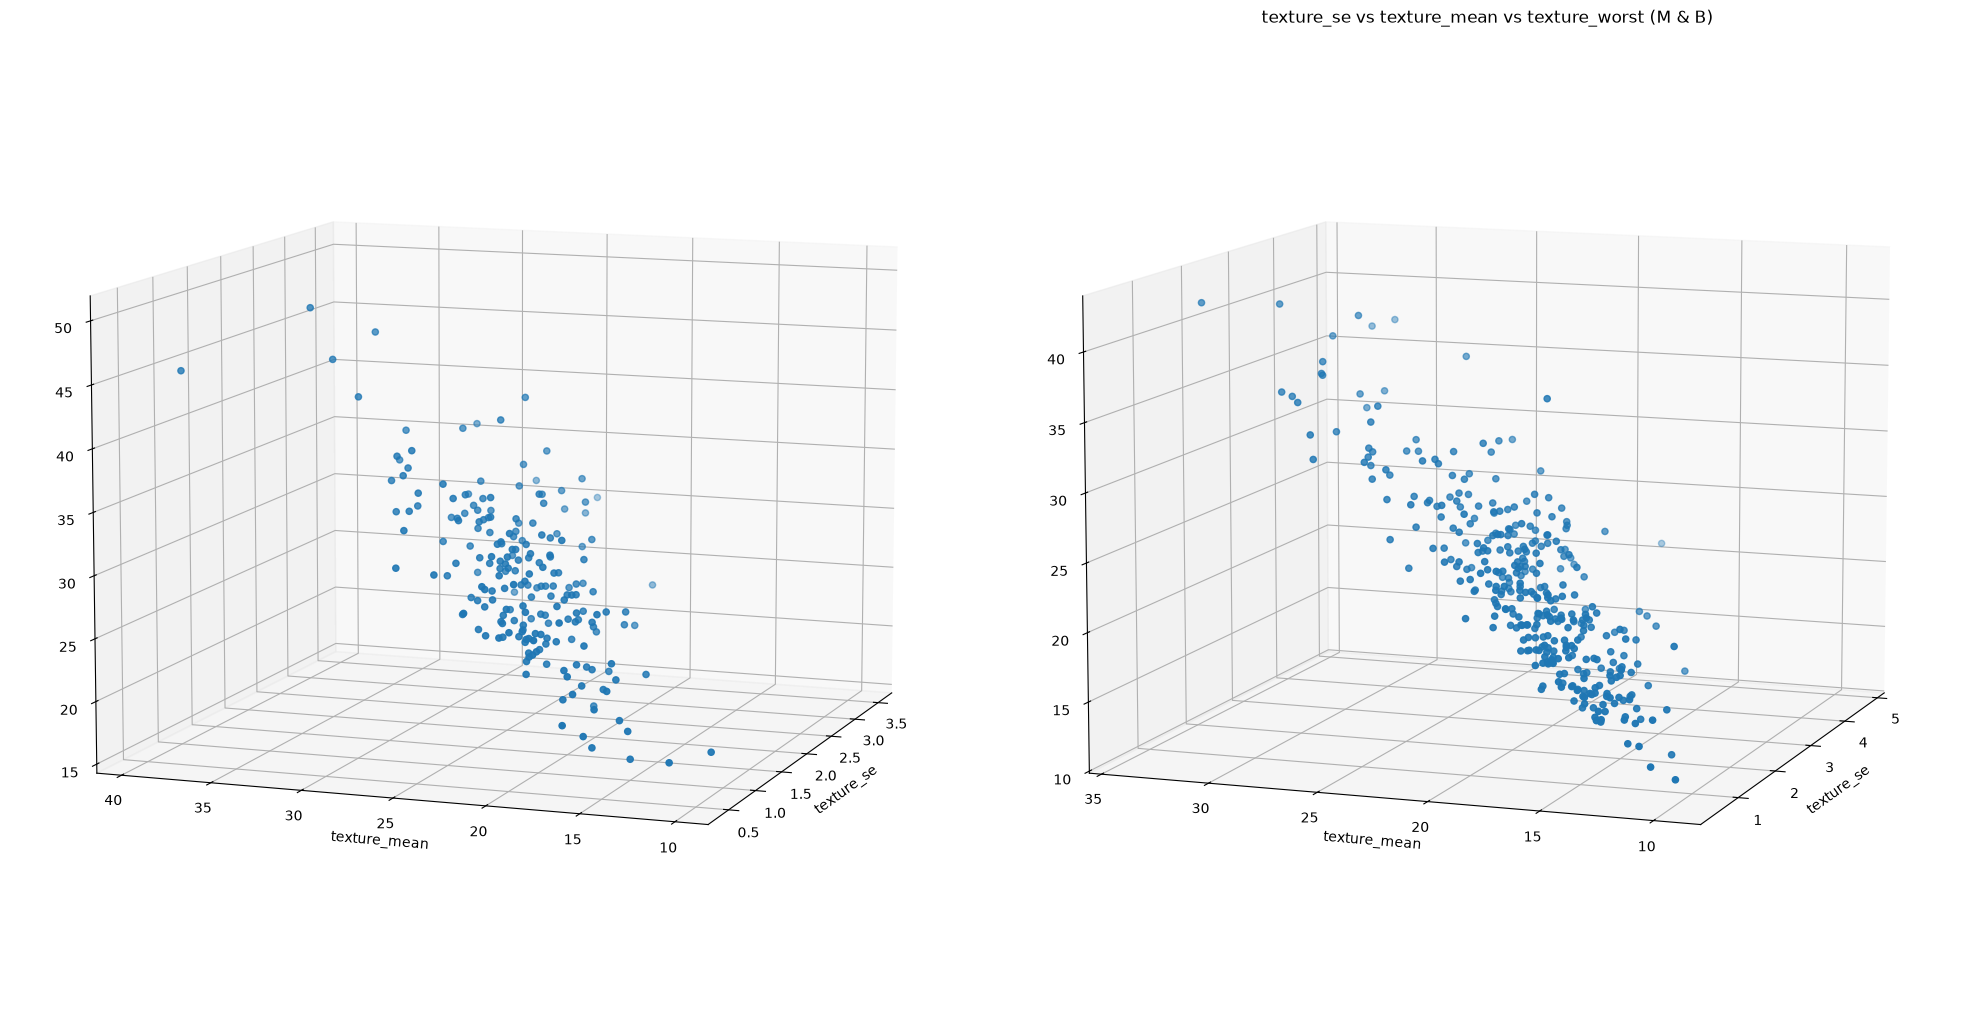

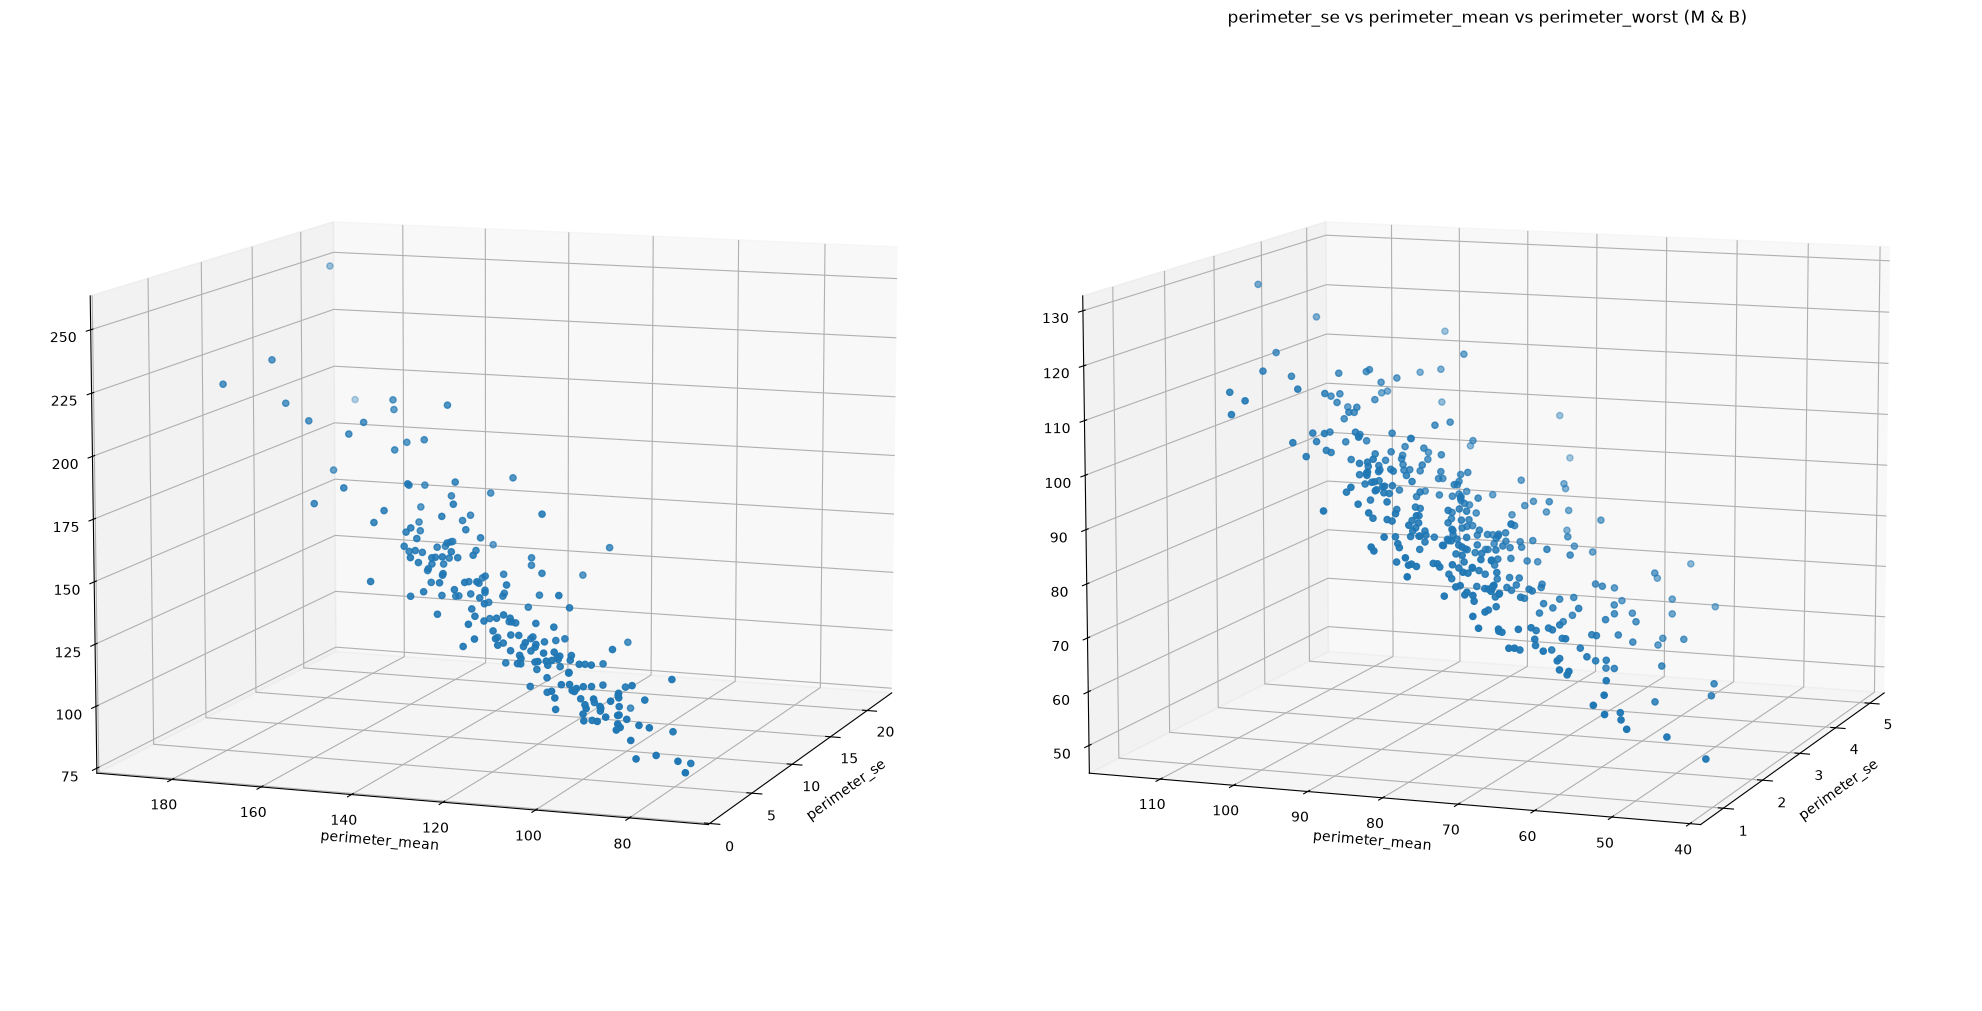

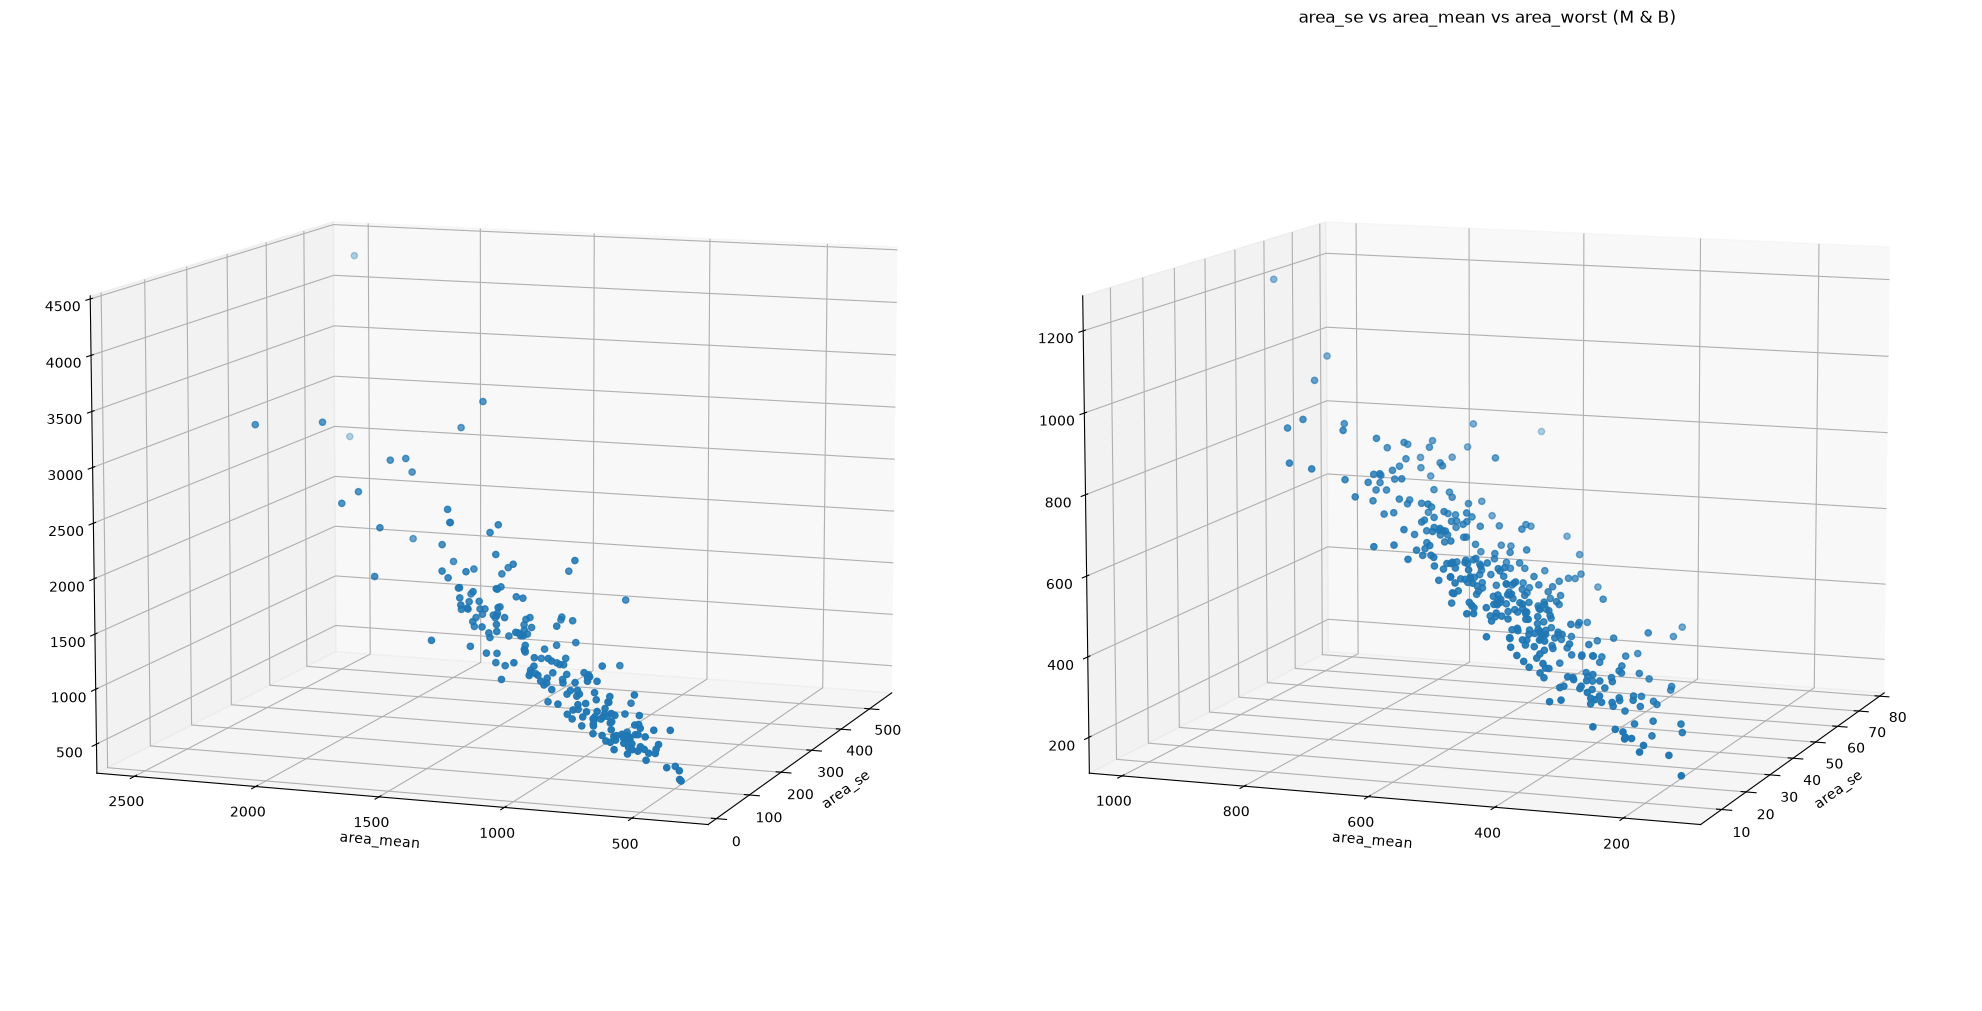

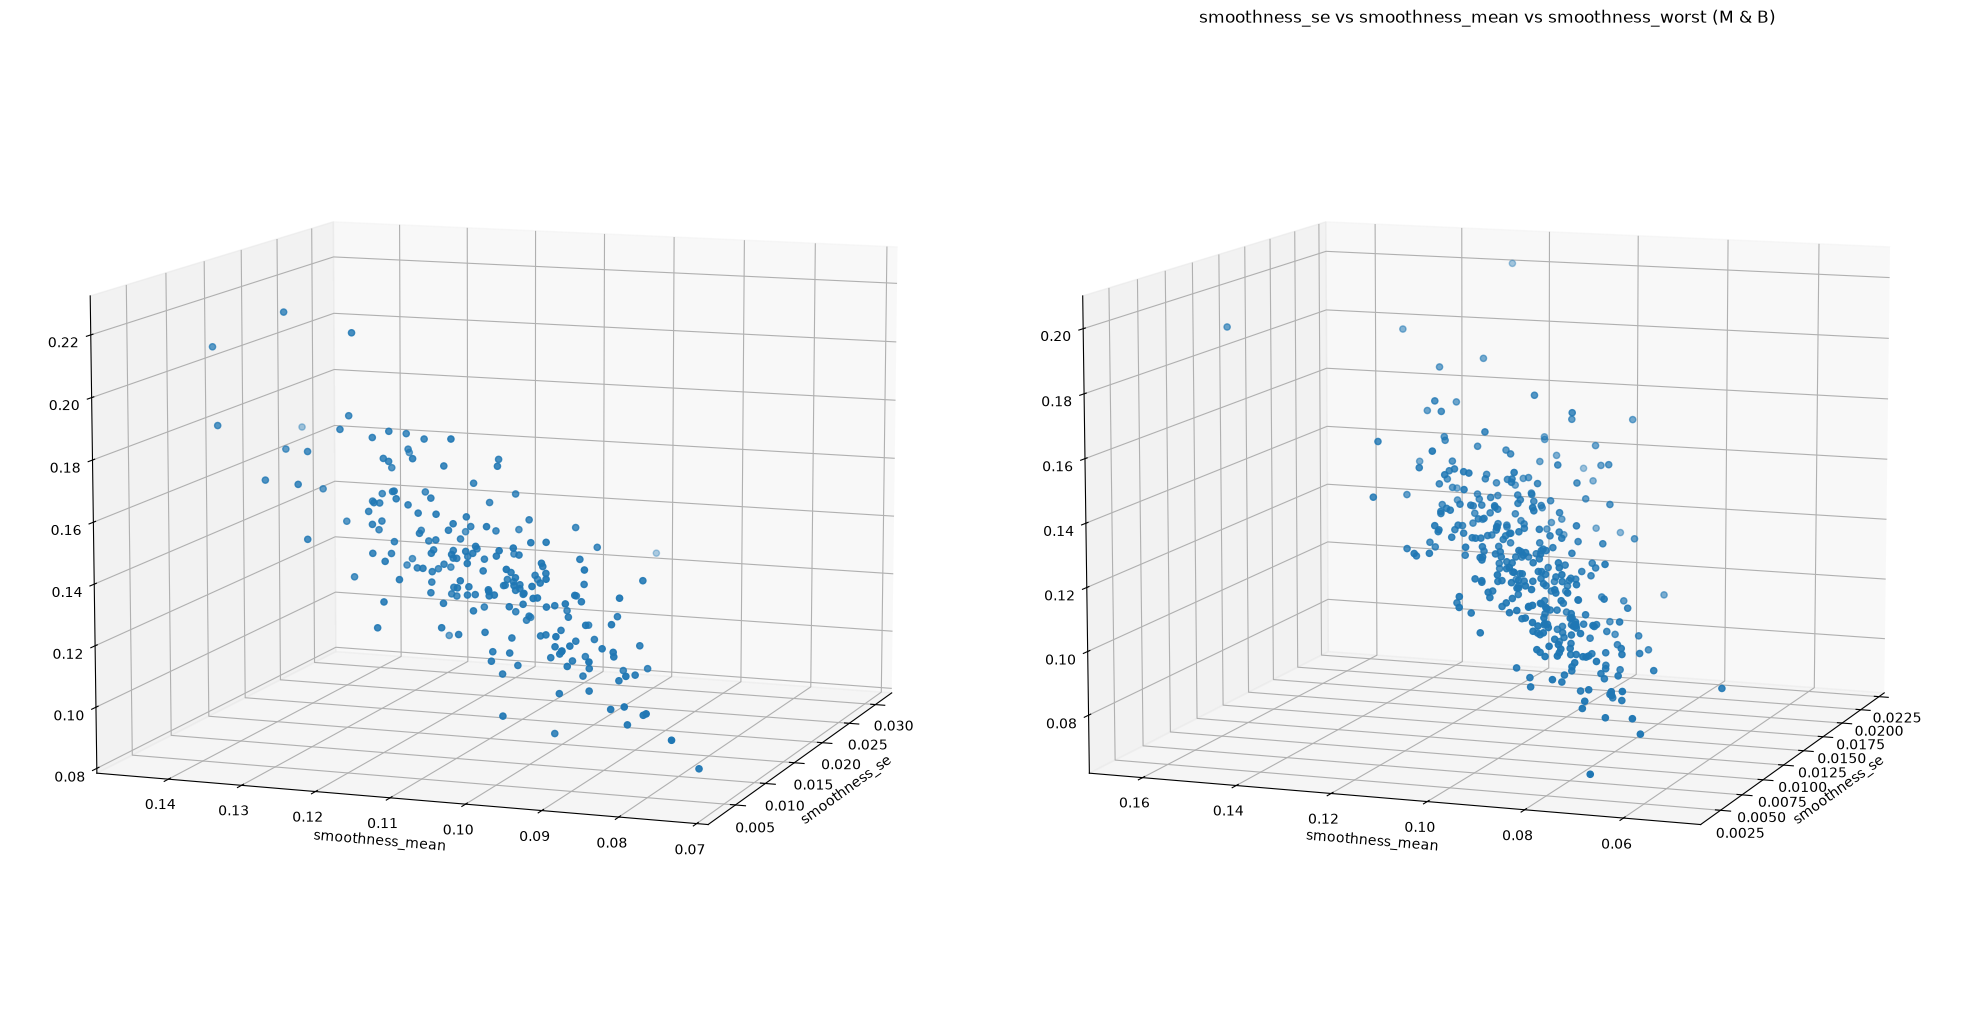

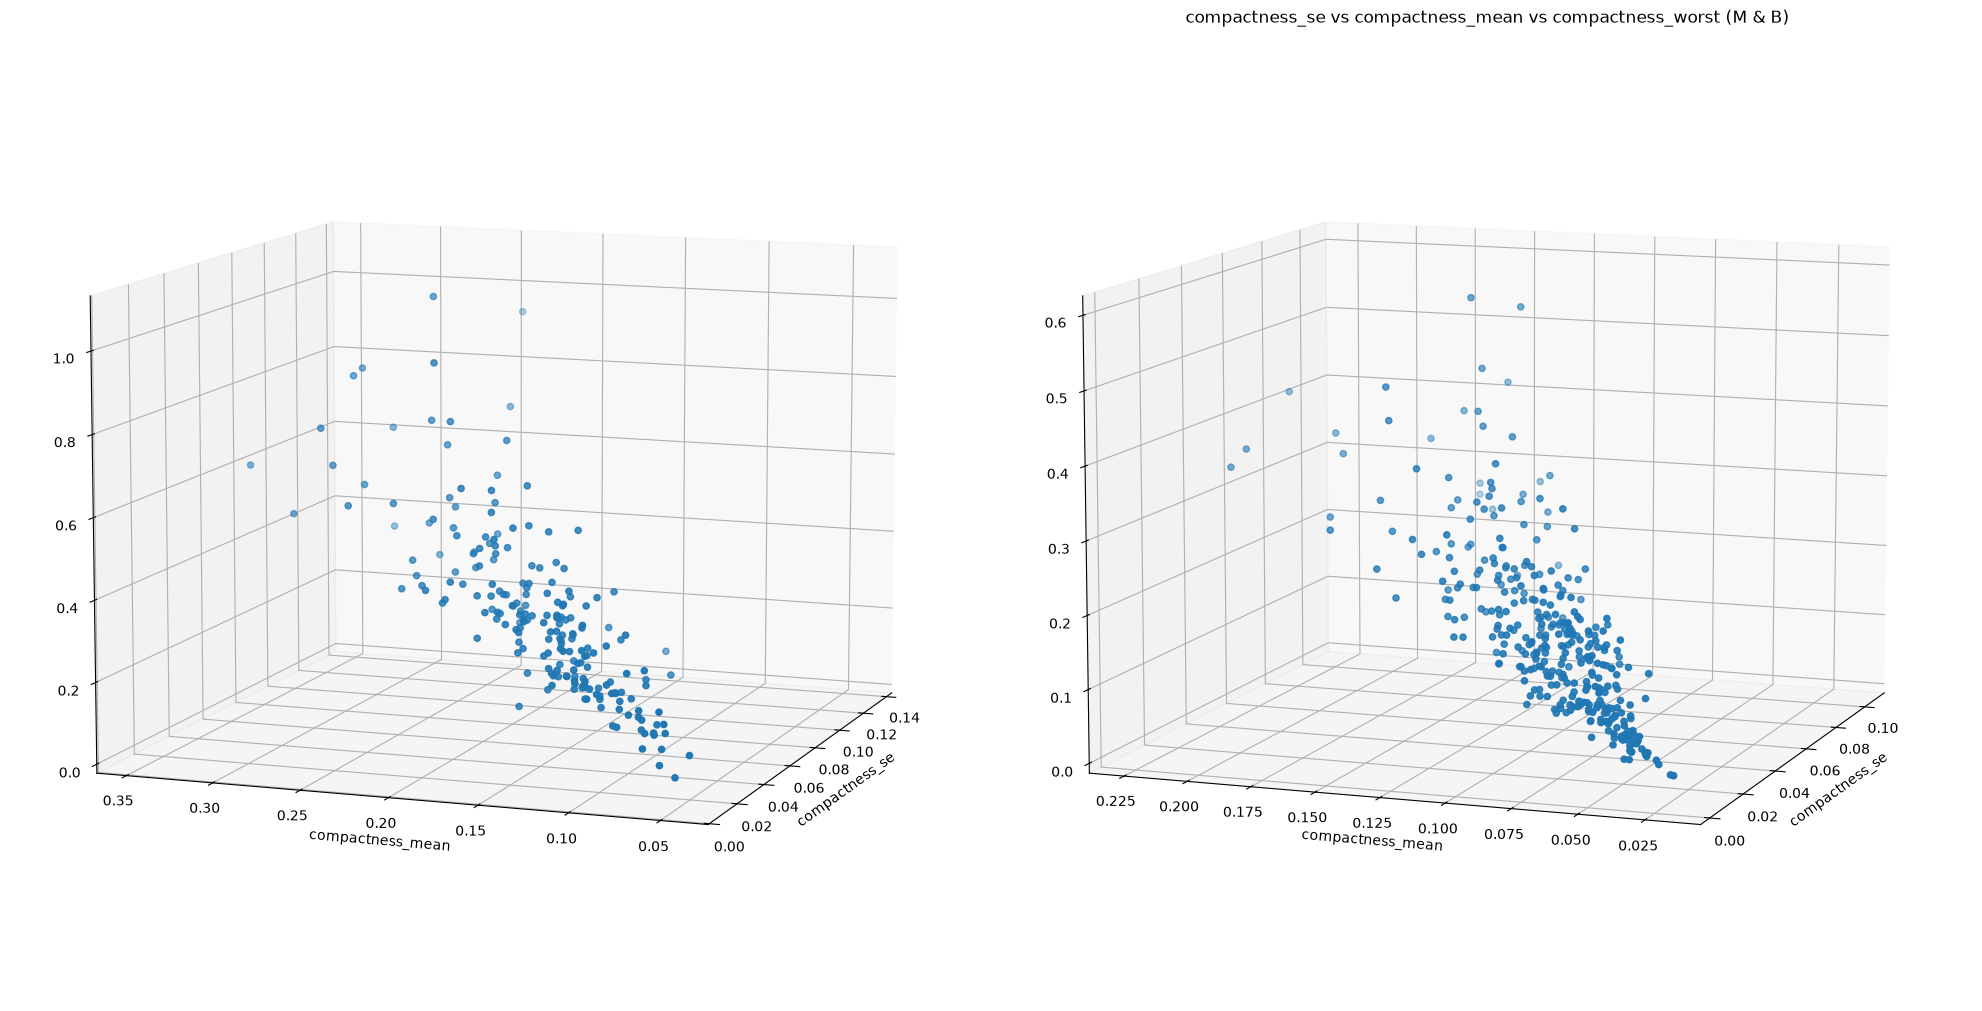

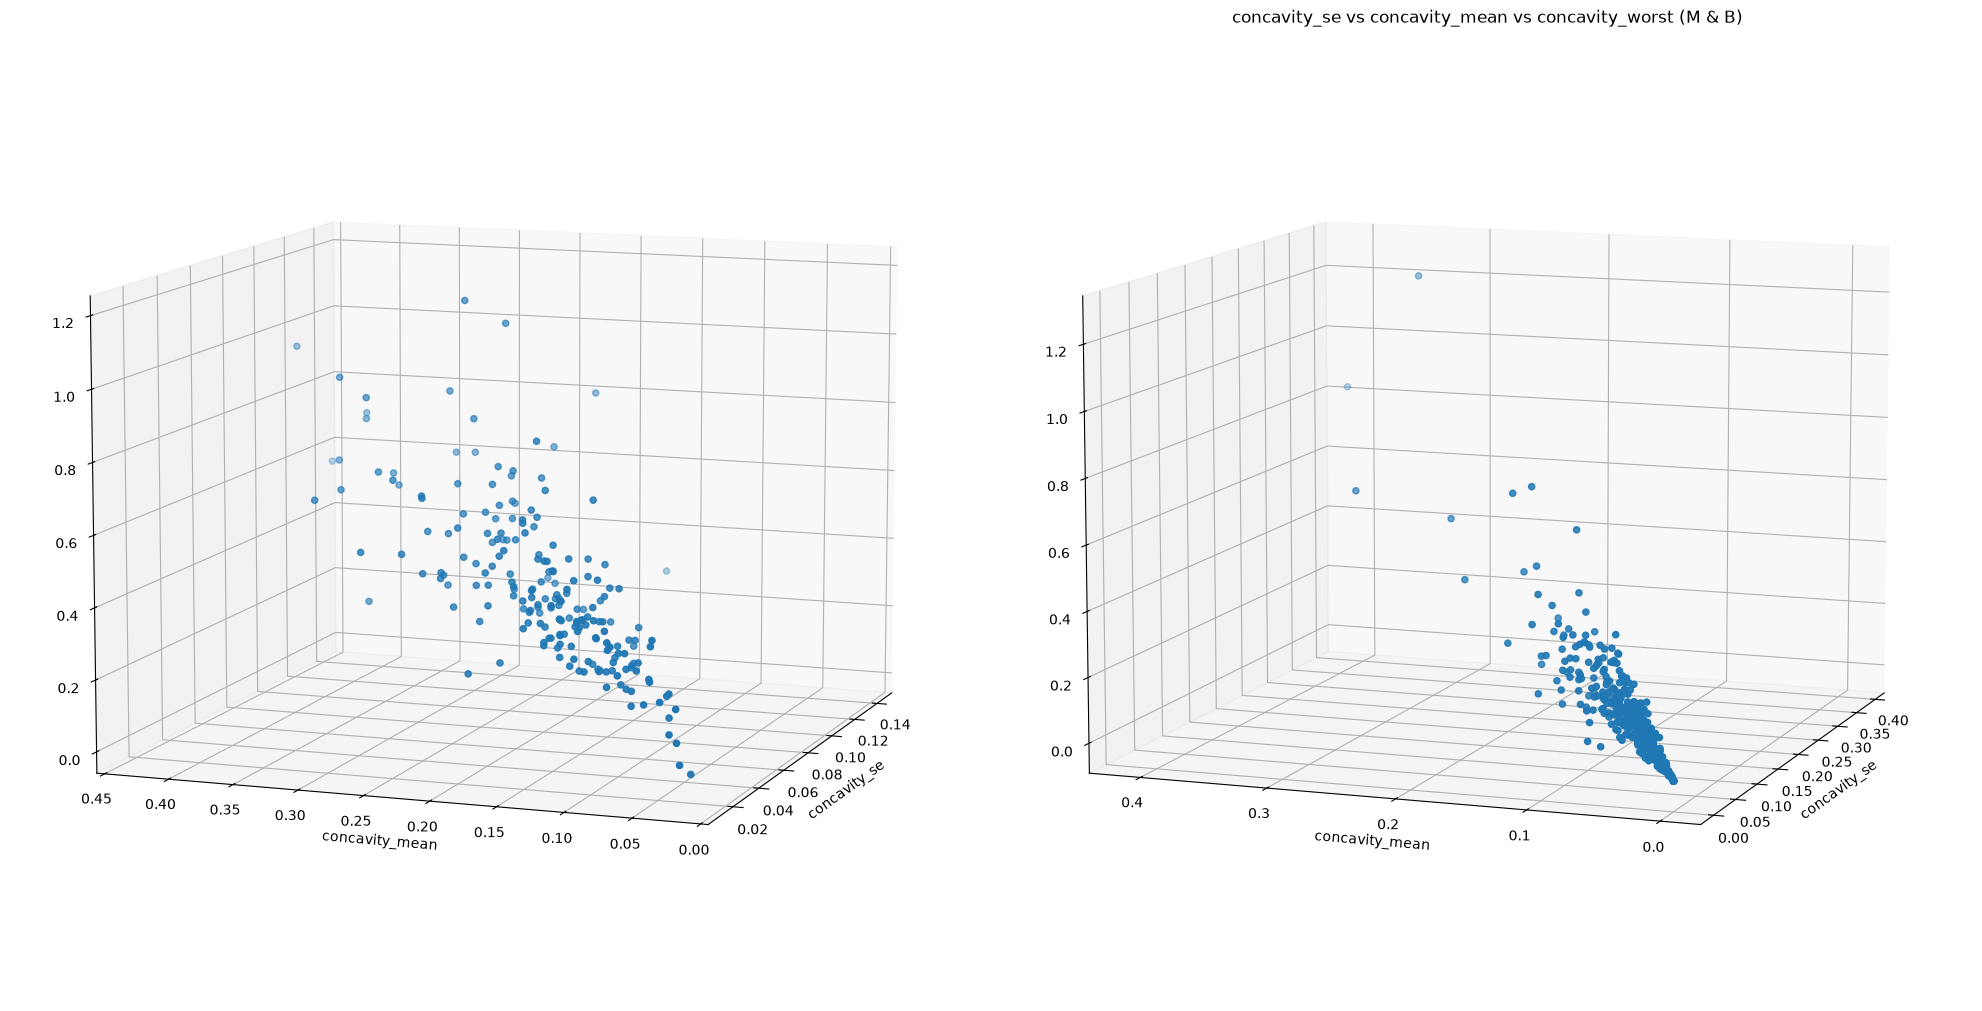

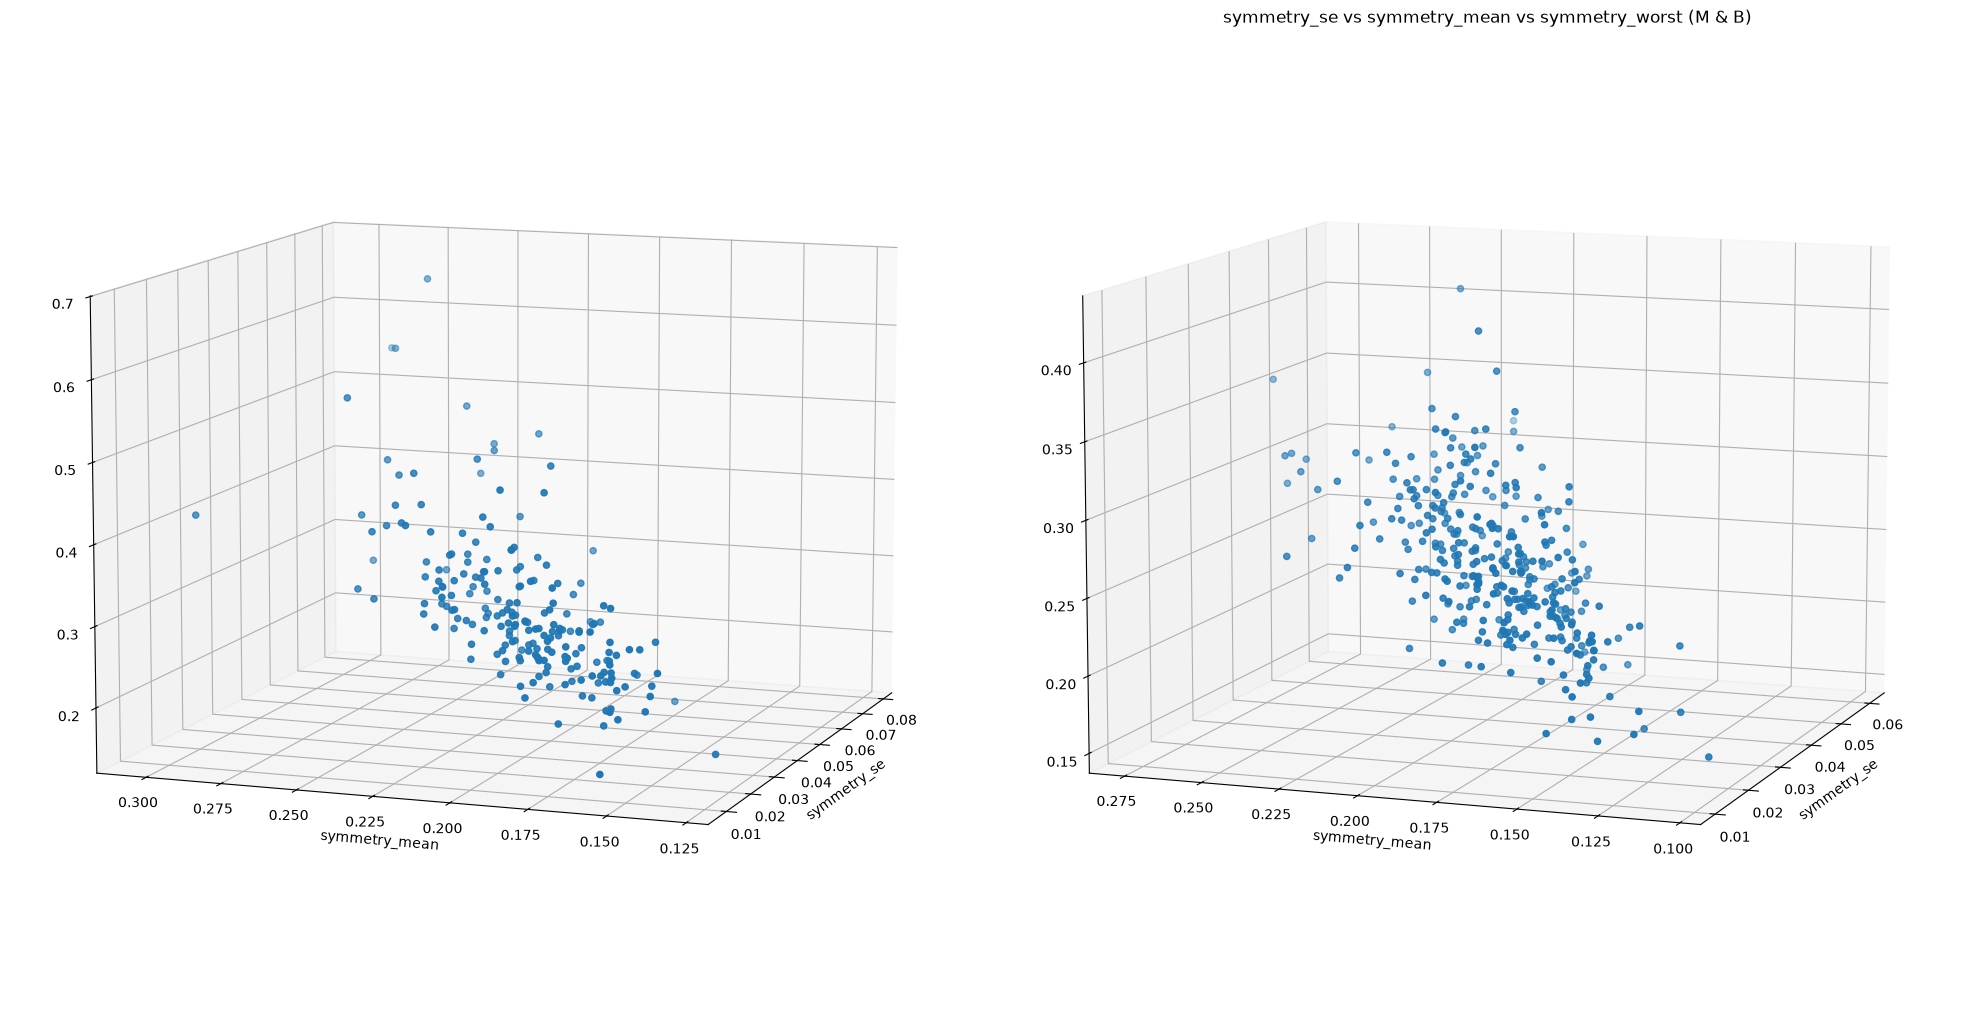

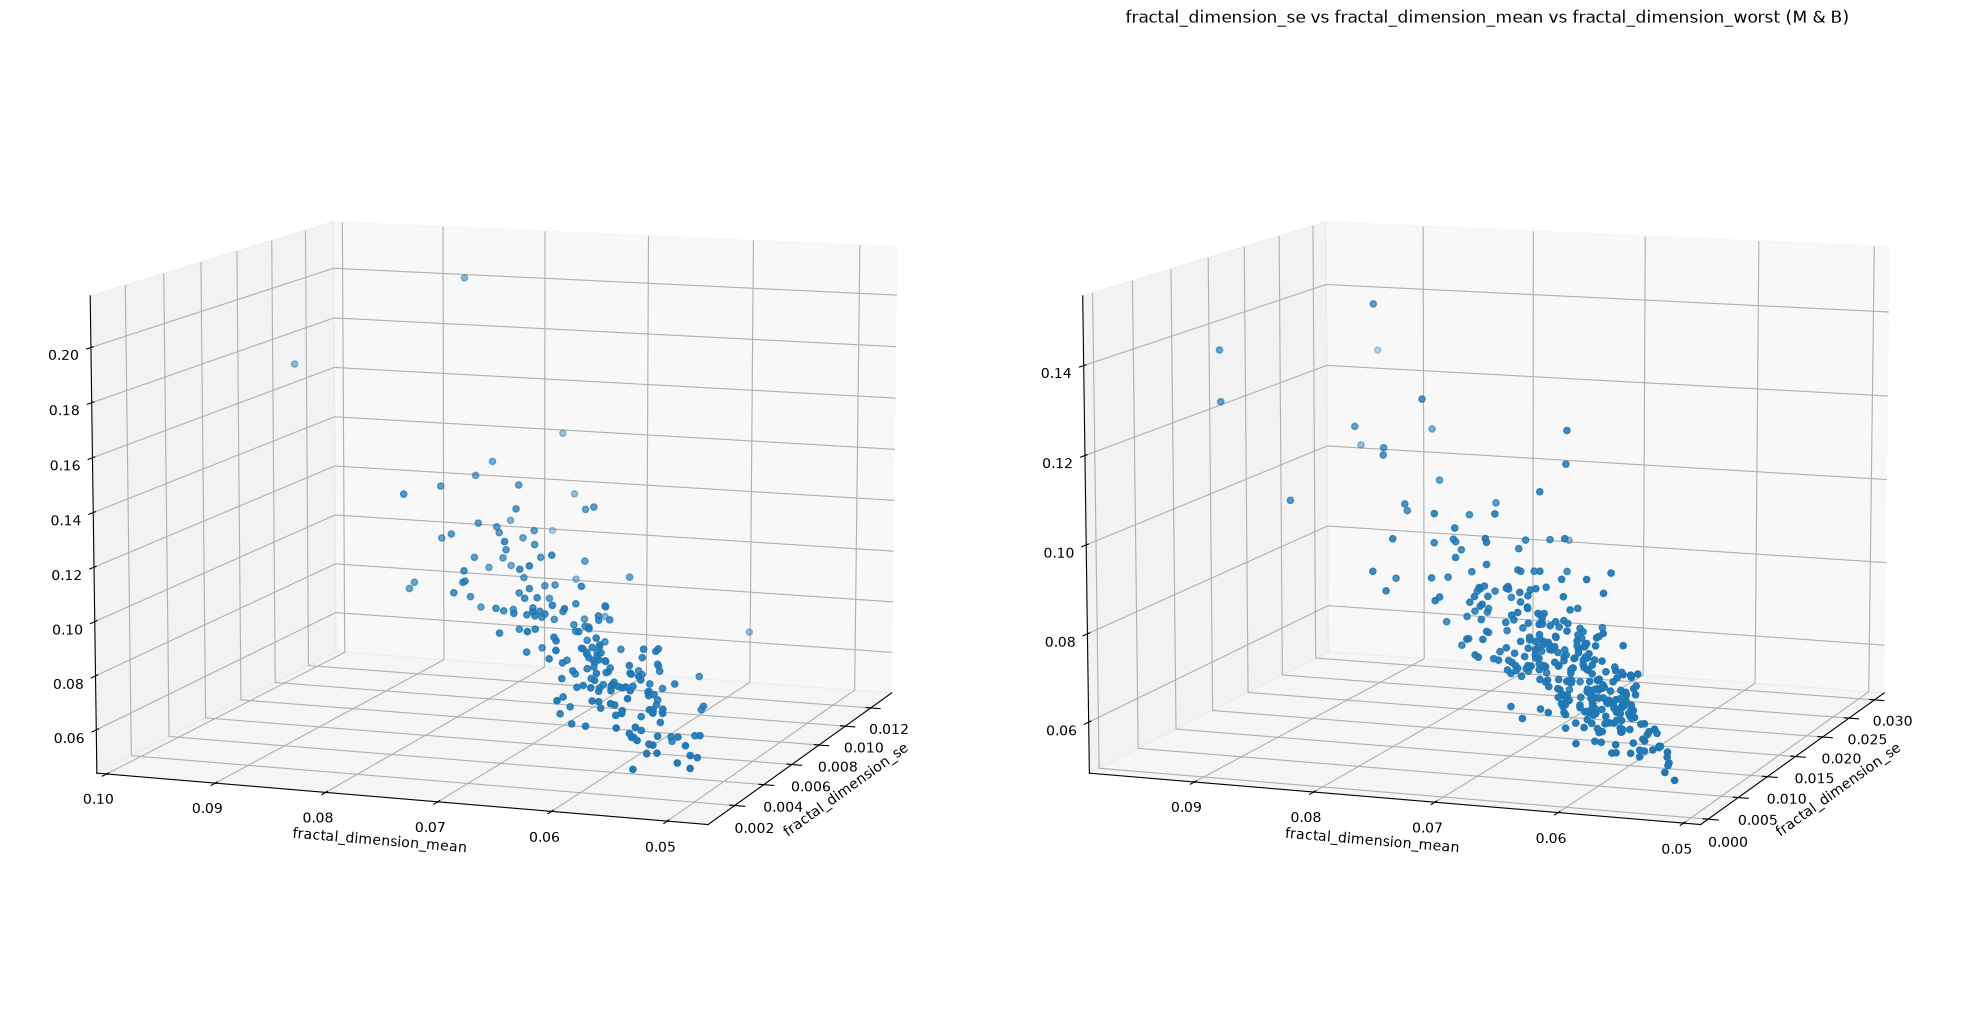

In [127]:
pairs: list[tuple[str, str]] = [
    ('radius_se', 'radius_mean', 'radius_worst'),
    ('texture_se', 'texture_mean', 'texture_worst'),
    ('perimeter_se', 'perimeter_mean', 'perimeter_worst'),
    ('area_se', 'area_mean', 'area_worst'),
    ('smoothness_se', 'smoothness_mean', 'smoothness_worst'),
    ('compactness_se', 'compactness_mean', 'compactness_worst'),
    ('concavity_se', 'concavity_mean', 'concavity_worst'),
    ('symmetry_se', 'symmetry_mean', 'symmetry_worst'),
    ('fractal_dimension_se', 'fractal_dimension_mean', 'fractal_dimension_worst'),
]

for x_col, y_col, z_col in pairs:
    figure, axis = plt.subplots(1, 2, subplot_kw={'projection': '3d'})
    figure.set_figheight(10)
    figure.set_figwidth(20)
    plt.title(f"{x_col} vs {y_col} vs {z_col} (M & B)")

    subset1 = data[data['diagnosis'] == 'M']
    subset2 = data[data['diagnosis'] == 'B']
    axis[0].set_xlabel(x_col)
    axis[1].set_xlabel(x_col)
    axis[0].set_ylabel(y_col)
    axis[1].set_ylabel(y_col)
    axis[0].scatter(subset1[x_col], subset1[y_col], subset1[z_col])
    axis[1].scatter(subset2[x_col], subset2[y_col], subset2[z_col])

    axis[0].view_init(elev=10, azim=200, roll=0)
    axis[1].view_init(elev=10, azim=200, roll=0)

    plt.tight_layout()
    plt.show()

# 5. Divisão de amostras de treino e teste

In [128]:
TEST_SIZE = 0.2
RANDOM_STATE = 42
N_JOBS = -1
CV_SPLITS = 5

y = pd.Series([0 if diagnosis == "B" else 1 for diagnosis in y.values], dtype=bool)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

In [129]:
print('Formato de x:', x.shape)
print('Formato de y:', y.shape)

print("\nx_train:", x_train.shape)
print("x_test :", x_test.shape)

print("\nDistribuição em y_train: (False = B, True = M)")
print(y_train.value_counts())
print("\nDistribuição em y_test: (False = B, True = M)")
print(y_test.value_counts())

Formato de x: (569, 30)
Formato de y: (569,)

x_train: (455, 30)
x_test : (114, 30)

Distribuição em y_train: (False = B, True = M)
False    285
True     170
Name: count, dtype: int64

Distribuição em y_test: (False = B, True = M)
False    72
True     42
Name: count, dtype: int64


# 6. Pré-processamento dos dados

In [ ]:
params_dict = {
    "svm_linear": (SVC(kernel="linear", cache_size=1000, random_state=RANDOM_STATE), {
        "clf__C": [0.001, 0.01, 0.1, 1, 10],
        "clf__class_weight": [None, "balanced"],
    }),
    "svm_rbf": (SVC(kernel="rbf", cache_size=1000, random_state=RANDOM_STATE), {
        "clf__C": [10, 75, 100, 125, 200],
        "clf__class_weight": [None],
        "clf__gamma": ["scale", "auto", 0.1, 1, 2, 10],
    }),
    "svm_poly": (SVC(kernel="poly", cache_size=1000, random_state=RANDOM_STATE), {
        "clf__C": [0.01, 0.1, 1, 10, 20],
        "clf__class_weight": [None, "balanced"],
        "clf__coef0": [1, 3, 5],
        "clf__gamma": [0.01, 0.1, 0.5],
    }),
    "svm_sigmoid": (SVC(kernel="sigmoid", cache_size=1000, random_state=RANDOM_STATE), {
        "clf__C": [1, 10, 50, 100],
        "clf__class_weight": [None, "balanced"],
        "clf__coef0": [0, 0.5, 1],
        "clf__gamma": [0.0001, 0.001, 0.01],
    }),
    "decision_tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        'clf__class_weight': ['balanced'],
        'clf__criterion': ['gini', 'entropy'],
        'clf__max_depth': [None, 10, 20, 40],
        'clf__max_features': [None, 'sqrt', 'log2'],
        'clf__min_samples_leaf': [2, 4, 10],
        'clf__min_samples_split': [2, 5, 10],
    }),
    "random_forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS), {
        'clf__class_weight': [None, 'balanced'],
        'clf__max_depth': [None, 10, 20],
        'clf__max_features': ['sqrt', 'log2'],
        'clf__min_samples_leaf': [1, 2],
        'clf__min_samples_split': [2, 5],
        'clf__n_estimators': [200, 500],
    }),
    "xgboost": (XGBClassifier(
        objective='binary:logistic',
        eval_metric='mlogloss',
        tree_method='hist',   # fast and Kaggle-friendly
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    ), {
        'clf__colsample_bytree': [0.1, 0.5],
        'clf__learning_rate': [0.1, 0.5, 1],
        'clf__max_depth': [4, 6, 8, 10],
        'clf__n_estimators': [200, 500],
        'clf__reg_lambda': [0.1, 0.5, 1.0],
        'clf__subsample': [0.5, 1.0],
    }),
}

# 7. Treinamento do modelo

=============== Treinando SVM_LINEAR... ===============
Fitting 5 folds for each of 10 candidates, totalling 50 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 9.61s


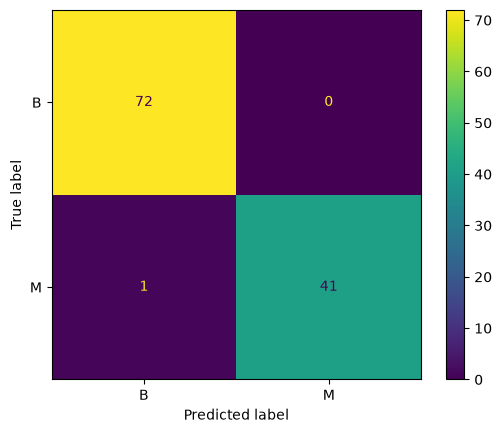

,3,4,5,6,7
mean_fit_time,0.021841,0.024798,0.023485,0.02183,0.021378
std_fit_time,0.002105,0.004744,0.00149,0.001134,0.001136
mean_score_time,0.011999,0.012128,0.012234,0.010426,0.010178
std_score_time,0.000967,0.003538,0.000853,0.00136,0.002221
param_clf__C,0.01,0.1,0.1,1.0,1.0
param_clf__class_weight,balanced,NaN,balanced,NaN,balanced
params,"{'clf__C': 0.01, 'clf__class_weight': 'balanced'}","{'clf__C': 0.1, 'clf__class_weight': None}","{'clf__C': 0.1, 'clf__class_weight': 'balanced'}","{'clf__C': 1, 'clf__class_weight': None}","{'clf__C': 1, 'clf__class_weight': 'balanced'}"
split0_test_score,0.967033,0.956044,0.945055,0.945055,0.945055
split1_test_score,0.967033,0.967033,0.967033,0.978022,0.978022
split2_test_score,0.978022,0.967033,0.967033,0.967033,0.967033


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


None

=============== Treinando SVM_RBF... ===============
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.78s


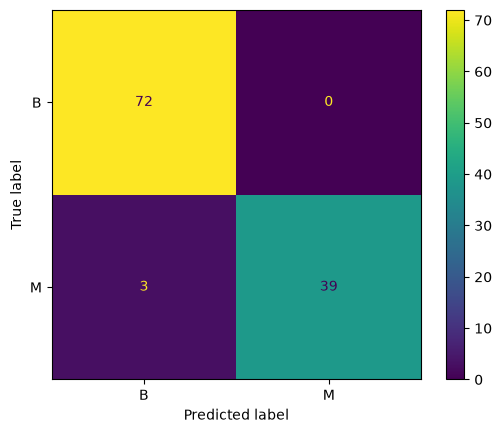

,0,1,6,7,12
mean_fit_time,0.017605,0.019258,0.017921,0.017554,0.018934
std_fit_time,0.002894,0.002989,0.002321,0.001605,0.005513
mean_score_time,0.009293,0.011516,0.009742,0.011497,0.008505
std_score_time,0.001244,0.002375,0.00181,0.004861,0.001077
param_clf__C,10,10,75,75,100
param_clf__class_weight,None,None,None,None,None
param_clf__gamma,scale,auto,scale,auto,scale
params,"{'clf__C': 10, 'clf__class_weight': None, 'clf...","{'clf__C': 10, 'clf__class_weight': None, 'clf...","{'clf__C': 75, 'clf__class_weight': None, 'clf...","{'clf__C': 75, 'clf__class_weight': None, 'clf...","{'clf__C': 100, 'clf__class_weight': None, 'cl..."
split0_test_score,0.967033,0.967033,0.956044,0.956044,0.956044
split1_test_score,0.989011,0.989011,0.956044,0.956044,0.956044


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


None

=============== Treinando SVM_POLY... ===============
Fitting 5 folds for each of 90 candidates, totalling 450 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 1.68s


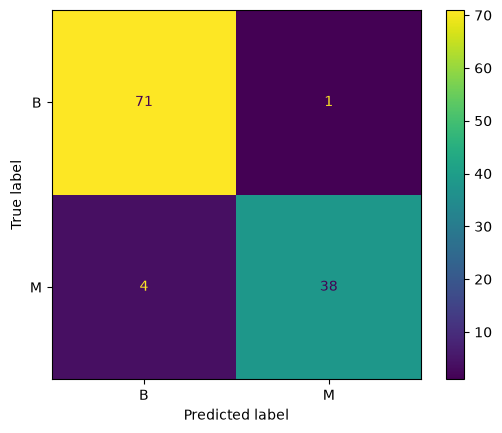

,22,31,16,19,28
mean_fit_time,0.016832,0.017075,0.017171,0.01592,0.018935
std_fit_time,0.001322,0.001797,0.000979,0.003298,0.003527
mean_score_time,0.008653,0.006996,0.007882,0.008539,0.007187
std_score_time,0.001527,0.000828,0.000906,0.0028,0.001521
param_clf__C,0.1,0.1,0.01,0.1,0.1
param_clf__class_weight,NaN,balanced,balanced,NaN,balanced
param_clf__coef0,3,3,5,1,1
param_clf__gamma,0.1,0.1,0.1,0.1,0.1
params,"{'clf__C': 0.1, 'clf__class_weight': None, 'cl...","{'clf__C': 0.1, 'clf__class_weight': 'balanced...","{'clf__C': 0.01, 'clf__class_weight': 'balance...","{'clf__C': 0.1, 'clf__class_weight': None, 'cl...","{'clf__C': 0.1, 'clf__class_weight': 'balanced..."
split0_test_score,0.967033,0.967033,0.956044,0.956044,0.967033


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


None

=============== Treinando SVM_SIGMOID... ===============
Fitting 5 folds for each of 72 candidates, totalling 360 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 1.53s


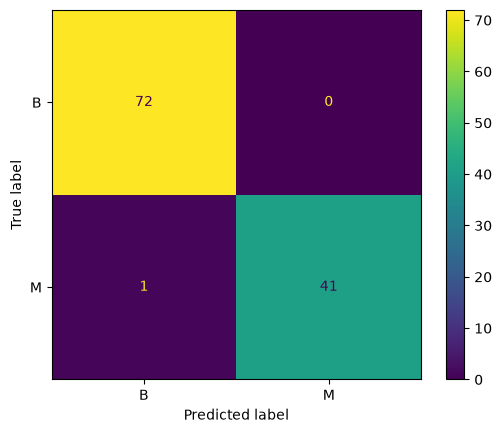

,28,63,40,31,52
mean_fit_time,0.018902,0.017903,0.025025,0.015567,0.019606
std_fit_time,0.000986,0.002148,0.010609,0.001467,0.001447
mean_score_time,0.008615,0.007736,0.009097,0.006399,0.008882
std_score_time,0.00069,0.000691,0.001248,0.002249,0.000929
param_clf__C,10,100,50,10,50
param_clf__class_weight,balanced,balanced,NaN,balanced,balanced
param_clf__coef0,0.0,0.0,0.5,0.5,1.0
param_clf__gamma,0.001,0.0001,0.001,0.001,0.001
params,"{'clf__C': 10, 'clf__class_weight': 'balanced'...","{'clf__C': 100, 'clf__class_weight': 'balanced...","{'clf__C': 50, 'clf__class_weight': None, 'clf...","{'clf__C': 10, 'clf__class_weight': 'balanced'...","{'clf__C': 50, 'clf__class_weight': 'balanced'..."
split0_test_score,0.967033,0.967033,0.956044,0.967033,0.956044


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


None

=============== Treinando DECISION_TREE... ===============
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 6.35s


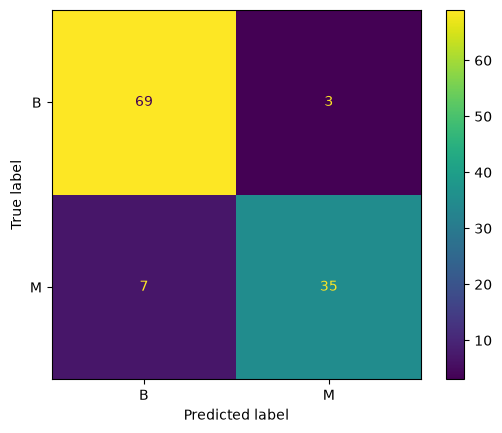

,3,4,5,31,30
mean_fit_time,0.022172,0.013408,0.015652,0.022805,0.020281
std_fit_time,0.00273,0.001199,0.000846,0.001013,0.003272
mean_score_time,0.006918,0.005141,0.005639,0.007414,0.007728
std_score_time,0.001705,0.001254,0.000843,0.000927,0.002074
param_clf__class_weight,balanced,balanced,balanced,balanced,balanced
param_clf__criterion,gini,gini,gini,gini,gini
param_clf__max_depth,None,None,None,10,10
param_clf__max_features,NaN,NaN,NaN,NaN,NaN
param_clf__min_samples_leaf,4,4,4,4,4
param_clf__min_samples_split,2,5,10,5,2


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


None

=============== Treinando RANDOM_FOREST... ===============
Fitting 5 folds for each of 96 candidates, totalling 480 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.4s
Modelo treinado em 85.53s


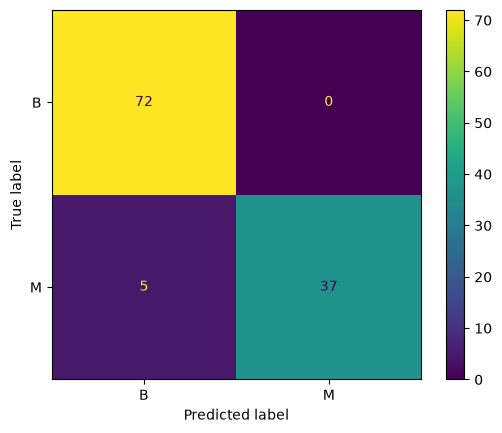

,24,8,49,40,81
mean_fit_time,0.80591,1.420647,2.327833,0.951776,2.669994
std_fit_time,0.03465,0.277135,0.027734,0.020541,0.062446
mean_score_time,0.099693,0.267848,0.233527,0.119468,0.283338
std_score_time,0.009454,0.048643,0.009651,0.011935,0.021469
param_clf__class_weight,NaN,NaN,balanced,NaN,balanced
param_clf__max_depth,10,None,None,20,20
param_clf__max_features,log2,log2,sqrt,log2,sqrt
param_clf__min_samples_leaf,1,1,1,1,1
param_clf__min_samples_split,2,2,2,2,2
param_clf__n_estimators,200,200,500,200,500


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


None

=============== Treinando XGBOOST... ===============
Fitting 5 folds for each of 1296 candidates, totalling 6480 fits


KeyboardInterrupt: 

In [136]:
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
results, cv_tables = [], {}

for classifier, (clf, param_grid) in params_dict.items():
    print("=" * 15, f"Treinando {classifier.upper()}...", "=" * 15)

    pipeline: Pipeline = Pipeline([
        ('prep', StandardScaler()),
        ('clf', clf)
    ], verbose=True)
    
    search = GridSearchCV(pipeline,  param_grid=param_grid, cv=cv, scoring="accuracy", n_jobs=N_JOBS, refit=True, verbose=True)

    start = time.monotonic()
    search.fit(x_train, y_train)
    elapsed = time.monotonic() - start

    print(f"Modelo treinado em {elapsed:.2f}s")

    y_pred = search.predict(x_test)

    cv_tables[classifier] = pd.DataFrame(search.cv_results_).sort_values(by="rank_test_score")

    ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred), display_labels=["B", "M"]).plot()

    display(
        cv_tables[classifier][:5].transpose(),
        search.best_estimator_,
        plt.show()
    )

    results.append({
        "classifier": classifier,
        "cv_best_score": search.best_score_,
    })

In [ ]:
results_df = pd.DataFrame(results)

results_df.set_index(keys="classifier").sort_values(by=["cv_best_score"], ascending=False)

,cv_best_score
classifier,
svm_poly,0.982418
xgboost,0.980220
svm_rbf,0.975824
svm_linear,0.973626
svm_sigmoid,0.973626
